<a href="https://colab.research.google.com/github/mprado06/TALLER-GRAFICOS/blob/main/Taller_Graficos_Publicacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts** para Gemini, en el mismo Colab.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [42]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

producto
Cuaderno          20712345
Block de notas    14292347
Resma carta       13133570
Marcador          10020786
Colores x12        9419625
Name: total, dtype: int64


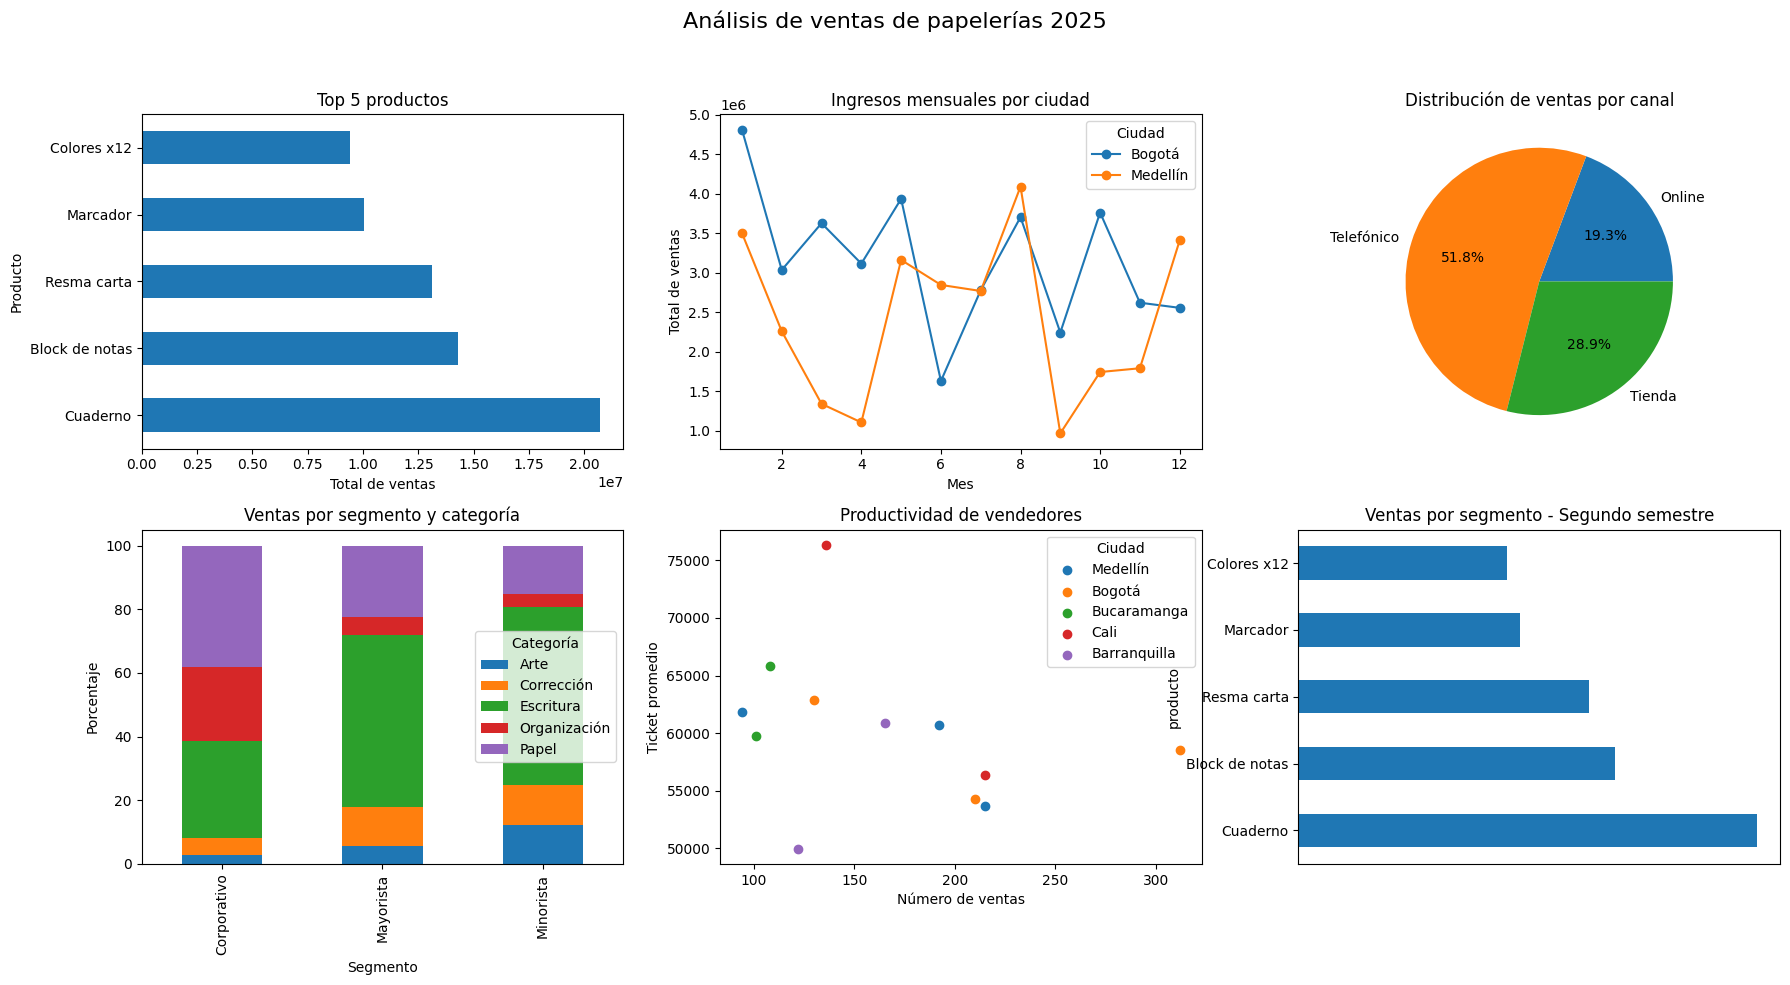

In [43]:
# Ejercicio 1
import matplotlib.pyplot as plt
#esto muestra la grafica
# se juntan las filas por productom y se suma el total de estas
top_productos = (df.groupby("producto")["total"]
                 .sum()
                 .sort_values(ascending=False)
                 .head(5))

print(top_productos)

top_productos.plot.barh()
plt.show()

### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

ciudad   Bogotá  Medellín
mes                      
1       4815405   3504905
2       3037200   2262080
3       3629385   1342665
4       3117990   1107910
5       3937775   3164730
6       1631810   2848235
7       2781218   2771377
8       3706217   4092446
9       2245001    969551
10      3764217   1745735
11      2623333   1793448
12      2558063   3412380


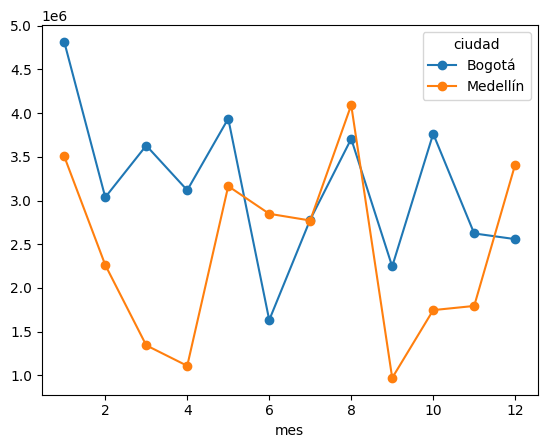

In [44]:
# Ejercicio 2

import matplotlib.pyplot as plt

df_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

ing_mes_ciudad = pd.pivot_table(df_ciudades,
                                index="mes",
                                columns="ciudad",
                                values="total",
                                aggfunc="sum")

print(ing_mes_ciudad)

ing_mes_ciudad.plot.line(marker="o")
plt.show()

### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

canal
Online        22887574
Telefónico    61450716
Tienda        34329722
Name: total, dtype: int64


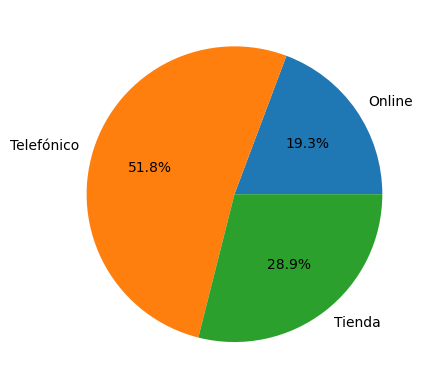

In [45]:
# Ejercicio 3

import matplotlib.pyplot as plt

ing_canal = df.groupby("canal")["total"].sum()

print(ing_canal)

ing_canal.plot.pie(autopct="%1.1f%%")
plt.ylabel("")
plt.show()

### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

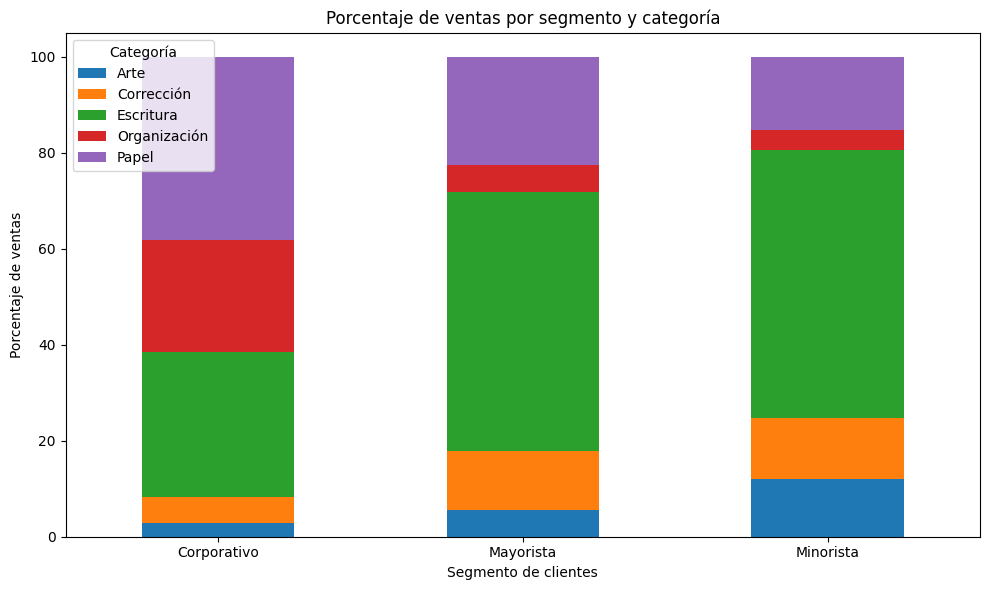

In [46]:
# Ejercicio 4

tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

tabla_seg_cat.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Porcentaje de ventas por segmento y categoría")
plt.xlabel("Segmento de clientes")
plt.ylabel("Porcentaje de ventas")
plt.legend(title="Categoría")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

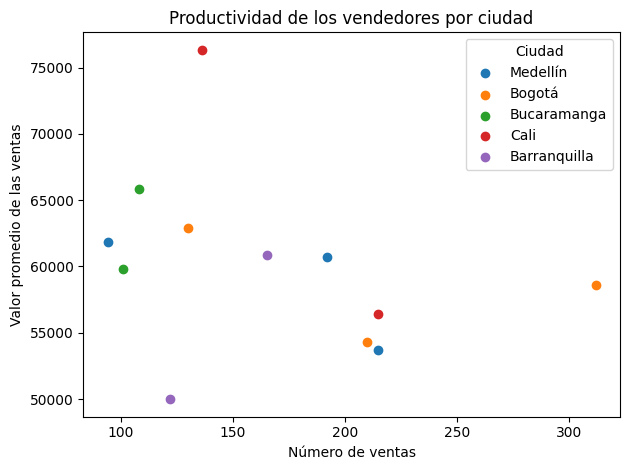

In [47]:
# Ejercicio 5

vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

for ciudad in vend["ciudad"].unique():

    datos = vend[vend["ciudad"] == ciudad]

    plt.scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad
    )

plt.title("Productividad de los vendedores por ciudad")
plt.xlabel("Número de ventas")
plt.ylabel("Valor promedio de las ventas")
plt.legend(title="Ciudad")
plt.tight_layout()
plt.show()

### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

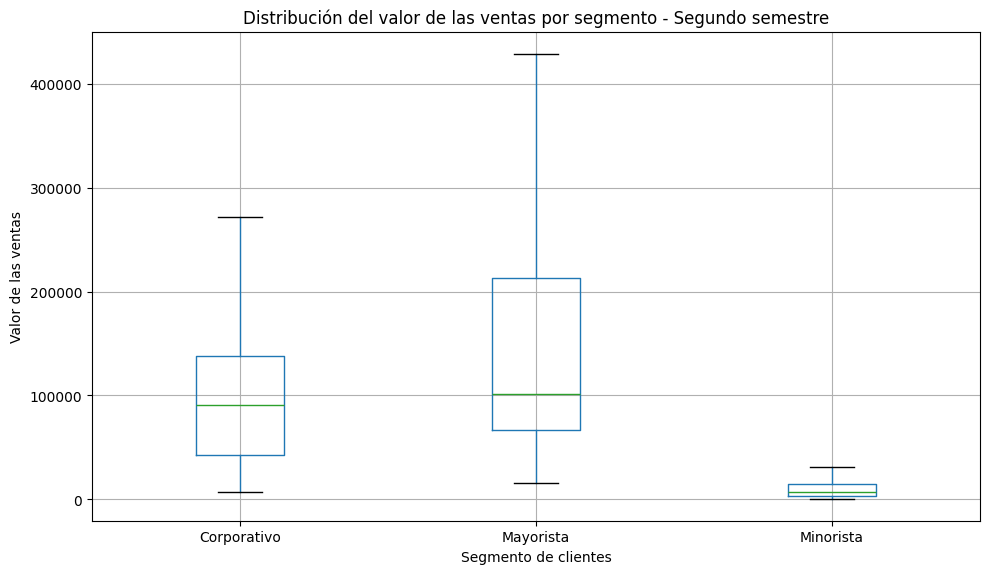

In [48]:
# Ejercicio 6

sem2 = df[pd.to_datetime(df["fecha"]).dt.month >= 7].copy()

sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    figsize=(10, 6)
)

plt.suptitle("")
plt.title("Distribución del valor de las ventas por segmento - Segundo semestre")
plt.xlabel("Segmento de clientes")
plt.ylabel("Valor de las ventas")
plt.tight_layout()
plt.show()

---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [49]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))

import matplotlib.pyplot as plt

# Ejercicio 7: seis gráficos en una figura 2x3

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# GRÁFICO 1: Top 5 productos
top_productos.plot.barh(ax=axs[0, 0])

axs[0, 0].set_title("Top 5 productos")
axs[0, 0].set_xlabel("Total de ventas")
axs[0, 0].set_ylabel("Producto")

# GRÁFICO 2: Ingresos por mes en Bogotá y Medellín
ing_mes_ciudad.plot.line(
    marker="o",
    ax=axs[0, 1]
)

axs[0, 1].set_title("Ingresos mensuales por ciudad")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Total de ventas")
axs[0, 1].legend(title="Ciudad")

# GRÁFICO 3: Ventas por canal
ing_canal.plot.pie(
    autopct="%1.1f%%",
    ax=axs[0, 2]
)

axs[0, 2].set_title("Distribución de ventas por canal")
axs[0, 2].set_ylabel("")

# GRÁFICO 4: Barras apiladas por segmento y categoría
tabla_seg_cat.plot.bar(
    stacked=True,
    ax=axs[1, 0]
)

axs[1, 0].set_title("Ventas por segmento y categoría")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje")
axs[1, 0].legend(title="Categoría")

# GRÁFICO 5: Dispersión de productividad por ciudad
for ciudad in vend["ciudad"].unique():

    datos = vend[vend["ciudad"] == ciudad]

    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad
    )

axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio")
axs[1, 1].legend(title="Ciudad")

# GRÁFICO 6: Diagrama de cajas
sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    ax=axs[1, 2]
)

axs[1, 2].set_title("Ventas por segmento - Segundo semestre")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de ventas")

# Título general
fig.suptitle(
    "Análisis de ventas de papelerías 2025",
    fontsize=16
)

# Organizar los gráficos
plt.tight_layout(rect=[0, 0, 1, 0.95])




Overwriting figura_base.py


In [50]:
%run -i figura_base.py


In [51]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt y Gemini reescribe el código** de tu figura para que se vea profesional, casi como un dashboard.


### Herramientas *(ya están hechas)*
Ejecuta esta celda. Define dos funciones:

- **`embellecer(prompt, nombre)`**: envía tu prompt **junto con tu código de `figura_base.py`**, ejecuta el código nuevo que devuelve Gemini y muestra la figura. Cada versión queda guardada en `VERSIONES[nombre]`.
- **`mostrar(nombre)`**: vuelve a dibujar una versión guardada.

In [52]:
import re

VERSIONES = {}      # aquí se guarda el código de cada versión ("v1", "v2", ...)

REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual (puedes recalcular las tablas con el mismo código);
  cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def extraer_codigo(texto):
    """Devuelve el contenido del primer bloque de código ``` de la respuesta."""
    bloque = re.search(r"```(?:python)?\s*\n(.*?)```", texto, re.S)
    return bloque.group(1) if bloque else texto


def dibujar(codigo):
    """Ejecuta el código de una figura y la muestra."""
    import numpy as np
    plt.close("all")
    espacio = {"df": df, "pd": pd, "plt": plt, "np": np}
    exec(codigo, espacio)
    figura = espacio["fig"]
    display(figura)
    plt.close(figura)


def embellecer(prompt, nombre, modelo="gemini-flash-latest"):
    """Gemini reescribe tu figura según tu prompt; se ejecuta, se muestra y se guarda en VERSIONES."""
    codigo_actual = open("figura_base.py", encoding="utf-8").read()
    contenido = f"{prompt}\n\nEste es mi código actual:\n```python\n{codigo_actual}\n```{REGLAS_FIGURA}"
    respuesta = client.models.generate_content(model=modelo, contents=contenido)
    codigo = extraer_codigo(respuesta.text)
    try:
        dibujar(codigo)
    except Exception as e:
        print("❌ El código de Gemini falló:", type(e).__name__, e)
        print("Copia ese error en tu siguiente prompt y pídele que lo corrija.")
        return
    VERSIONES[nombre] = codigo
    print(f"✔ Versión '{nombre}' guardada")


def mostrar(nombre):
    """Vuelve a dibujar una versión guardada."""
    dibujar(VERSIONES[nombre])

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

In [63]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La figura la va a ver la gerencia de una cadena de papelerias en una reunión. Necesitan entender rapido en que productos conviene concentrar el inventario, como evolucionan Bogota y Medellin durante el año, que canal aporta mas ingresos y que compra cada segmento de clientes. Debe leerse en pocos segundos, sin explicacion extra.


PALETA Y TIPOGRAFÍA: Los colores de cada ciudad deben venir de su bandera. Bogotá en rojo y amarillo, y Medellín en verde (el blanco de su bandera no se vería sobre el fondo, así que uso solo el verde). Esos colores se usan solo para las ciudades. En los demás gráficos uso grises y un solo color de acento para resaltar el dato más importante. Fondo blanco. Texto en gris oscuro, no negro. Títulos en negrita de tamaño 14, ejes de tamaño 10 y números sobre las barras de tamaño 9. Una sola fuente sans-serif en toda la figura.


TÍTULOS: Cada gráfico debe tener un título que diga la conclusión y no solo el nombre. Por ejemplo "Dos productos concentran la mayor parte de los ingresos" o "Bogotá lidera las ventas casi todo el año". Los títulos deben salir de los datos reales, no inventados. Agrega también un título general para toda la figura, alineado a la izquierda.


EJES Y NÚMEROS: Los valores en pesos deben escribirse completos y con separador de miles con puntos, por ejemplo 12.000.000, sin abreviar con "M" ni con "mil". Esto aplica a los ejes y a los números sobre las barras. Los meses deben salir con nombre (Ene, Feb, Mar) y no como números. Cada eje debe tener una etiqueta clara con sus unidades. En el gráfico de pie, los porcentajes deben tener un decimal. En las barras apiladas, el eje va de 0 a 100 % y la leyenda debe tener título.


LIMPIEZA VISUAL: La gráfica debe ser minimalista y clara. Quita todos los bordes y marcos, y también las marcas de los ejes. Usa una cuadrícula muy suave y delgada, solo en horizontal, o ninguna si los valores ya están sobre las barras. Pon el valor sobre cada barra. En los gráficos de líneas, deja los marcadores y escribe el nombre de la ciudad al final de cada línea en vez de usar leyenda. No uses sombras, degradados ni efectos 3D. Deja mucho espacio en blanco entre los gráficos para que nada se superponga.
"""

print(prompt_v1)


PÚBLICO Y OBJETIVO: La figura la va a ver la gerencia de una cadena de papelerias en una reunión. Necesitan entender rapido en que productos conviene concentrar el inventario, como evolucionan Bogota y Medellin durante el año, que canal aporta mas ingresos y que compra cada segmento de clientes. Debe leerse en pocos segundos, sin explicacion extra.


PALETA Y TIPOGRAFÍA: Los colores de cada ciudad deben venir de su bandera. Bogotá en rojo y amarillo, y Medellín en verde (el blanco de su bandera no se vería sobre el fondo, así que uso solo el verde). Esos colores se usan solo para las ciudades. En los demás gráficos uso grises y un solo color de acento para resaltar el dato más importante. Fondo blanco. Texto en gris oscuro, no negro. Títulos en negrita de tamaño 14, ejes de tamaño 10 y números sobre las barras de tamaño 9. Una sola fuente sans-serif en toda la figura.


TÍTULOS: Cada gráfico debe tener un título que diga la conclusión y no solo el nombre. Por ejemplo "Dos productos co

In [69]:
%%writefile figura_v1.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

GRIS = "#4D4D4D"
GRIS_CLARO = "#C9C9C9"
ACENTO = "#1F4E79"
ROJO = "#C8102E"
VERDE = "#1B7F3B"
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]


def miles(x, pos=None):
    return f"{x:,.0f}".replace(",", ".")


def limpiar(ax):
    for lado in ["top", "right", "left", "bottom"]:
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0, colors=GRIS, labelsize=10)
    ax.set_facecolor("white")


def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=14, fontweight="bold", color=GRIS, pad=14)


def crear_figura(df):
    plt.rcParams["font.family"] = "sans-serif"
    fig, axs = plt.subplots(2, 2, figsize=(16, 10), facecolor="white")
    fig.subplots_adjust(hspace=0.55, wspace=0.4, top=0.87, left=0.08, right=0.95, bottom=0.08)
    fig.suptitle("Ventas de papelerías 2025", x=0.01, ha="left",
                 fontsize=18, fontweight="bold", color=GRIS)

    ax = axs[0, 0]
    limpiar(ax)
    top = (df.groupby("producto")["total"].sum()
           .sort_values(ascending=False).head(5).sort_values())
    colores = [ACENTO if i == len(top) - 1 else GRIS_CLARO for i in range(len(top))]
    ax.barh(top.index, top.values, color=colores)
    for y, v in enumerate(top.values):
        ax.text(v, y, "  " + miles(v), va="center", fontsize=9, color=GRIS)
    ax.set_xlim(0, top.max() * 1.25)
    ax.xaxis.set_major_formatter(FuncFormatter(miles))
    ax.set_xlabel("Ingresos (pesos)", fontsize=10, color=GRIS)
    ax.set_ylabel("Producto", fontsize=10, color=GRIS)
    titulo(ax, f"{top.index[-1]} es el producto que más ingresos genera")

    ax = axs[0, 1]
    limpiar(ax)
    sub = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    piv = pd.pivot_table(sub, index="mes", columns="ciudad", values="total", aggfunc="sum")
    colores_ciudad = {"Bogotá": ROJO, "Medellín": VERDE}
    for ciudad, color in colores_ciudad.items():
        if ciudad in piv.columns:
            ax.plot(piv.index, piv[ciudad], marker="o", color=color, linewidth=2.2)
            ax.text(piv.index[-1] + 0.2, piv[ciudad].iloc[-1], ciudad, color=color,
                    va="center", fontsize=10, fontweight="bold")
    ax.set_xticks(piv.index)
    ax.set_xticklabels([MESES[m - 1] for m in piv.index])
    ax.set_xlim(piv.index.min() - 0.3, piv.index.max() + 1.8)
    ax.yaxis.set_major_formatter(FuncFormatter(miles))
    ax.yaxis.grid(True, color="#EEEEEE", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel("Mes", fontsize=10, color=GRIS)
    ax.set_ylabel("Ingresos (pesos)", fontsize=10, color=GRIS)
    lider = piv.sum().idxmax()
    meses_lider = int((piv[lider] >= piv.max(axis=1)).sum())
    titulo(ax, f"{lider} lidera en {meses_lider} de {len(piv)} meses")

    ax = axs[1, 0]
    ing = df.groupby("canal")["total"].sum()
    paleta_pie = [ACENTO, GRIS_CLARO, "#7F9DB9", "#8C8C8C"]
    ax.pie(ing.values, labels=ing.index, autopct="%1.1f%%", startangle=90,
           colors=[paleta_pie[i % len(paleta_pie)] for i in range(len(ing))],
           wedgeprops={"edgecolor": "white", "linewidth": 2},
           textprops={"color": GRIS, "fontsize": 10})
    ax.set_ylabel("")
    titulo(ax, f"{ing.idxmax()} aporta {ing.max() / ing.sum() * 100:.1f}% de los ingresos")

    ax = axs[1, 1]
    limpiar(ax)
    tabla = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
    paleta = plt.cm.Blues(np.linspace(0.3, 0.9, len(tabla.columns)))
    tabla.plot.bar(stacked=True, ax=ax, color=paleta, width=0.6)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 5 else "" for v in c.datavalues],
                     label_type="center", fontsize=9, color="white")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0f} %"))
    ax.yaxis.grid(True, color="#EEEEEE", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)
    ax.set_xlabel("Segmento de clientes", fontsize=10, color=GRIS)
    ax.set_ylabel("Porcentaje de ventas", fontsize=10, color=GRIS)
    ax.legend(title="Categoría", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    dominante = tabla.idxmax(axis=1)
    if dominante.nunique() == 1:
        titulo(ax, f"{dominante.iloc[0]} domina en todos los segmentos")
    else:
        titulo(ax, "Cada segmento prioriza una categoría distinta")

    return fig



Overwriting figura_v1.py


<Figure size 640x480 with 0 Axes>

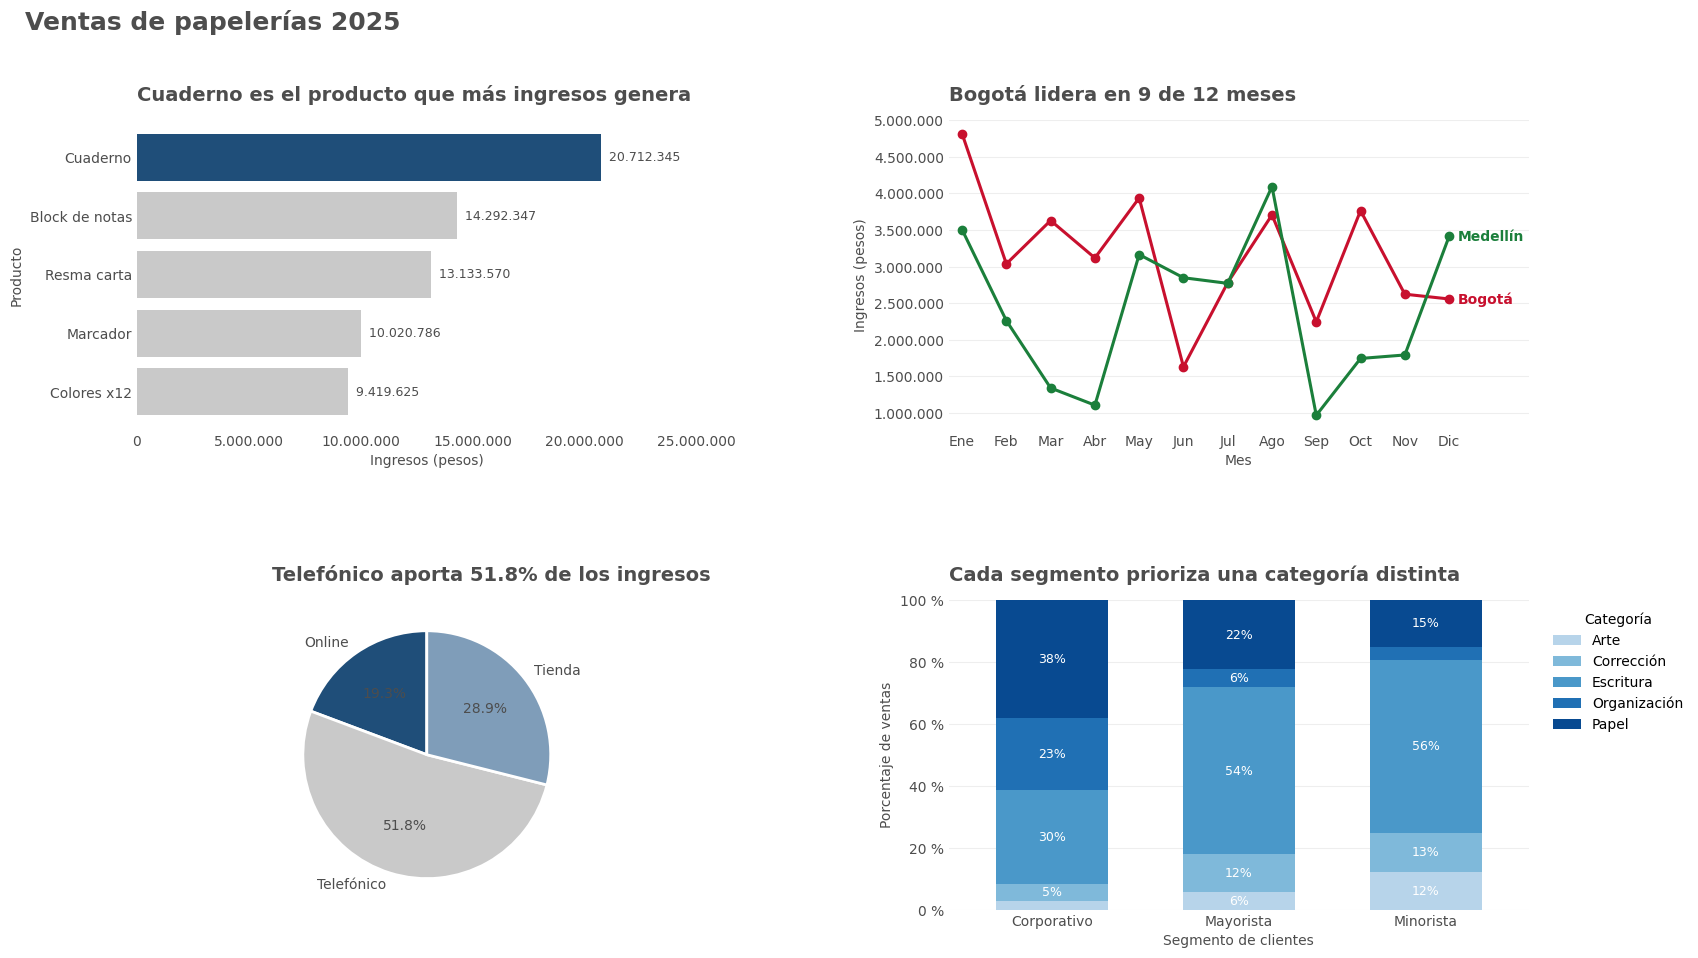

In [73]:
%run -i figura_v1.py

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month

fig = crear_figura(df)
plt.show()

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (por ejemplo: otra paleta, letras más grandes, anotar el valor máximo del gráfico de líneas, cambiar el pie por una dona…). Es la **iteración de prompts** que vimos en clase.

In [78]:

prompt_v2 = prompt_v1 + """

AJUSTES: 1.⁠ ⁠En el gráfico de barras de productos y en las barras apiladas de segmento por categoría, los tonos de azul se confunden entre sí. Quiero colores claramente distintos para cada producto y cada categoría, por ejemplo un rojo, un verde, un amarillo, un morado y un gris. Que se distingan a simple vista sin leer la leyenda. Se mantiene el rojo y amarillo para Bogotá y el verde para Medellín solo en el gráfico de líneas, así que en los otros gráficos no repitas esos colores con otro significado.
2.⁠ ⁠El gráfico de pie se ve confuso. Cámbialo por una dona (con el centro vacío) o por barras horizontales ordenadas de mayor a menor, lo que se lea mejor. Cada canal debe tener un color distinto, con el nombre y el porcentaje con un decimal escritos directamente sobre cada parte, sin leyenda aparte. Si hay un canal que aporta más, resáltalo.

"""

print(prompt_v2, "v2")


PÚBLICO Y OBJETIVO: La figura la va a ver la gerencia de una cadena de papelerias en una reunión. Necesitan entender rapido en que productos conviene concentrar el inventario, como evolucionan Bogota y Medellin durante el año, que canal aporta mas ingresos y que compra cada segmento de clientes. Debe leerse en pocos segundos, sin explicacion extra.


PALETA Y TIPOGRAFÍA: Los colores de cada ciudad deben venir de su bandera. Bogotá en rojo y amarillo, y Medellín en verde (el blanco de su bandera no se vería sobre el fondo, así que uso solo el verde). Esos colores se usan solo para las ciudades. En los demás gráficos uso grises y un solo color de acento para resaltar el dato más importante. Fondo blanco. Texto en gris oscuro, no negro. Títulos en negrita de tamaño 14, ejes de tamaño 10 y números sobre las barras de tamaño 9. Una sola fuente sans-serif en toda la figura.


TÍTULOS: Cada gráfico debe tener un título que diga la conclusión y no solo el nombre. Por ejemplo "Dos productos co

In [81]:
%%writefile figura_v2.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

GRIS = "#4D4D4D"
GRIS_CLARO = "#C9C9C9"
ROJO = "#C8102E"
AMARILLO = "#F2B705"
VERDE = "#1B7F3B"
PALETA = ["#1F77B4", "#7B3F98", "#E8751A", "#17A2A2", "#8C564B", "#6B6B6B"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]


def miles(x, pos=None):
    return f"{x:,.0f}".replace(",", ".")


def limpiar(ax):
    for lado in ["top", "right", "left", "bottom"]:
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0, colors=GRIS, labelsize=10)
    ax.set_facecolor("white")


def titulo(ax, texto):
    ax.set_title(texto, loc="left", fontsize=14, fontweight="bold", color=GRIS, pad=14)


def etiquetas_dona(nombres):
    contador = [0]

    def f(p):
        nombre = nombres[contador[0]]
        contador[0] += 1
        return f"{nombre}\n{p:.1f}%"

    return f


def crear_figura(df):
    plt.rcParams["font.family"] = "sans-serif"
    fig, axs = plt.subplots(2, 2, figsize=(16, 10), facecolor="white")
    fig.subplots_adjust(hspace=0.55, wspace=0.4, top=0.87, left=0.08, right=0.95, bottom=0.08)
    fig.suptitle("Ventas de papelerías 2025", x=0.01, ha="left",
                 fontsize=18, fontweight="bold", color=GRIS)

    ax = axs[0, 0]
    limpiar(ax)
    top = (df.groupby("producto")["total"].sum()
           .sort_values(ascending=False).head(5))
    colores_top = [PALETA[i % len(PALETA)] for i in range(len(top))]
    top_plot = top.iloc[::-1]
    colores_plot = colores_top[::-1]
    ax.barh(top_plot.index, top_plot.values, color=colores_plot)
    for y, v in enumerate(top_plot.values):
        ax.text(v, y, "  " + miles(v), va="center", fontsize=9, color=GRIS)
    ax.set_xlim(0, top.max() * 1.25)
    ax.xaxis.set_major_formatter(FuncFormatter(miles))
    ax.set_xlabel("Ingresos (pesos)", fontsize=10, color=GRIS)
    ax.set_ylabel("Producto", fontsize=10, color=GRIS)
    titulo(ax, f"{top.index[0]} es el producto que más ingresos genera")

    ax = axs[0, 1]
    limpiar(ax)
    sub = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    piv = pd.pivot_table(sub, index="mes", columns="ciudad", values="total", aggfunc="sum")
    colores_ciudad = {"Bogotá": ROJO, "Medellín": VERDE}
    for ciudad, color in colores_ciudad.items():
        if ciudad in piv.columns:
            relleno = AMARILLO if ciudad == "Bogotá" else color
            ax.plot(piv.index, piv[ciudad], marker="o", color=color, linewidth=2.2,
                    markerfacecolor=relleno, markeredgecolor=color, markersize=7)
            ax.text(piv.index[-1] + 0.2, piv[ciudad].iloc[-1], ciudad, color=color,
                    va="center", fontsize=10, fontweight="bold")
    ax.set_xticks(piv.index)
    ax.set_xticklabels([MESES[m - 1] for m in piv.index])
    ax.set_xlim(piv.index.min() - 0.3, piv.index.max() + 1.8)
    ax.yaxis.set_major_formatter(FuncFormatter(miles))
    ax.yaxis.grid(True, color="#EEEEEE", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel("Mes", fontsize=10, color=GRIS)
    ax.set_ylabel("Ingresos (pesos)", fontsize=10, color=GRIS)
    lider = piv.sum().idxmax()
    meses_lider = int((piv[lider] >= piv.max(axis=1)).sum())
    titulo(ax, f"{lider} lidera en {meses_lider} de {len(piv)} meses")

    ax = axs[1, 0]
    ing = df.groupby("canal")["total"].sum().sort_values(ascending=False)
    colores_canal = [PALETA[i % len(PALETA)] for i in range(len(ing))]
    explotar = [0.05 if i == 0 else 0 for i in range(len(ing))]
    ax.pie(ing.values, startangle=90, counterclock=False, colors=colores_canal,
           explode=explotar, autopct=etiquetas_dona(list(ing.index)), pctdistance=0.78,
           wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},
           textprops={"color": "white", "fontsize": 9, "fontweight": "bold"})
    ax.set_ylabel("")
    titulo(ax, f"{ing.idxmax()} aporta {ing.max() / ing.sum() * 100:.1f}% de los ingresos")

    ax = axs[1, 1]
    limpiar(ax)
    tabla = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
    colores_cat = [PALETA[i % len(PALETA)] for i in range(len(tabla.columns))]
    tabla.plot.bar(stacked=True, ax=ax, color=colores_cat, width=0.6)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 5 else "" for v in c.datavalues],
                     label_type="center", fontsize=9, color="white")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0f} %"))
    ax.yaxis.grid(True, color="#EEEEEE", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)
    ax.set_xlabel("Segmento de clientes", fontsize=10, color=GRIS)
    ax.set_ylabel("Porcentaje de ventas", fontsize=10, color=GRIS)
    ax.legend(title="Categoría", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    dominante = tabla.idxmax(axis=1)
    if dominante.nunique() == 1:
        titulo(ax, f"{dominante.iloc[0]} domina en todos los segmentos")
    else:
        titulo(ax, "Cada segmento prioriza una categoría distinta")

    return fig


df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month

fig = crear_figura(df)
plt.show()

Overwriting figura_v2.py


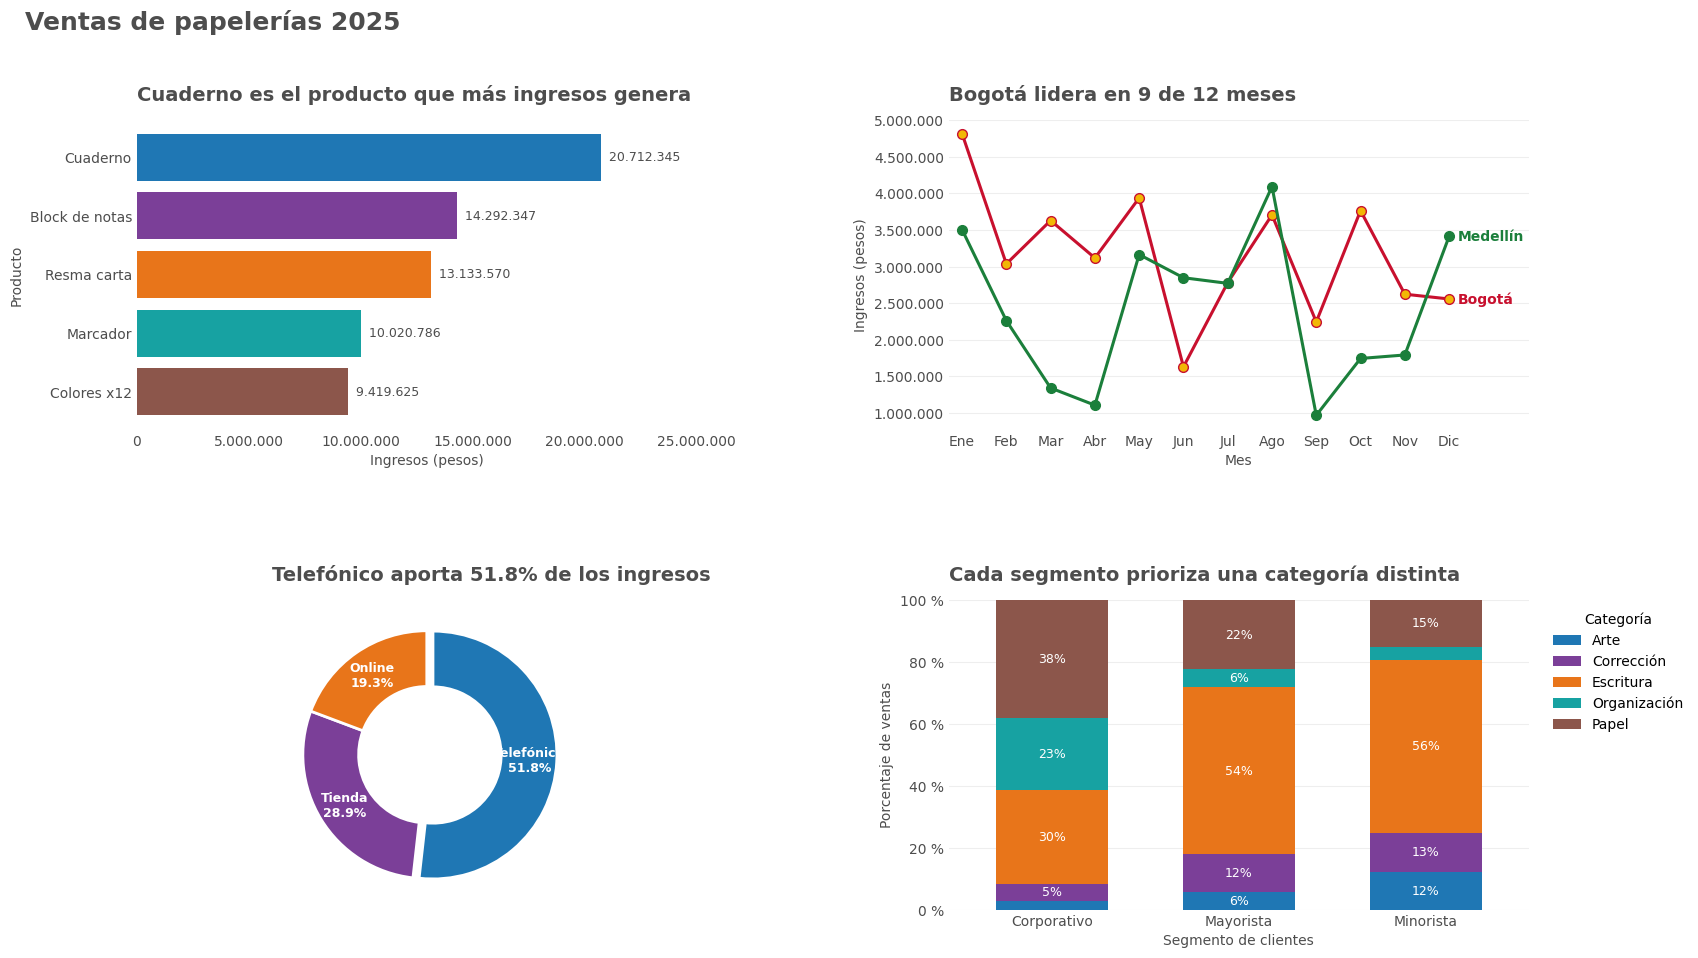

<Figure size 640x480 with 0 Axes>

In [83]:
%run -i figura_v2.py

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`) y ejecútalo con el nombre `"v3"`. Tendrás tres versiones para comparar.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# embellecer(prompt_v3, "v3")

In [ ]:
# ✅ Verificación
assert len(VERSIONES) >= 2, "Debes tener al menos dos versiones de tu figura (v1 y v2)"
print("Versiones guardadas:", list(VERSIONES), "· Parte C correcta ✔")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [84]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "Bogota lidera en 9 de los 12 meses",
    "Cuaderno es el producto que mas ingresos genera",
    "El producto que menos ingresos genera son los colores",
]

In [87]:
# ✅ Verificación
assert figura_elegida in VERSIONES, f"No existe la versión {figura_elegida}: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

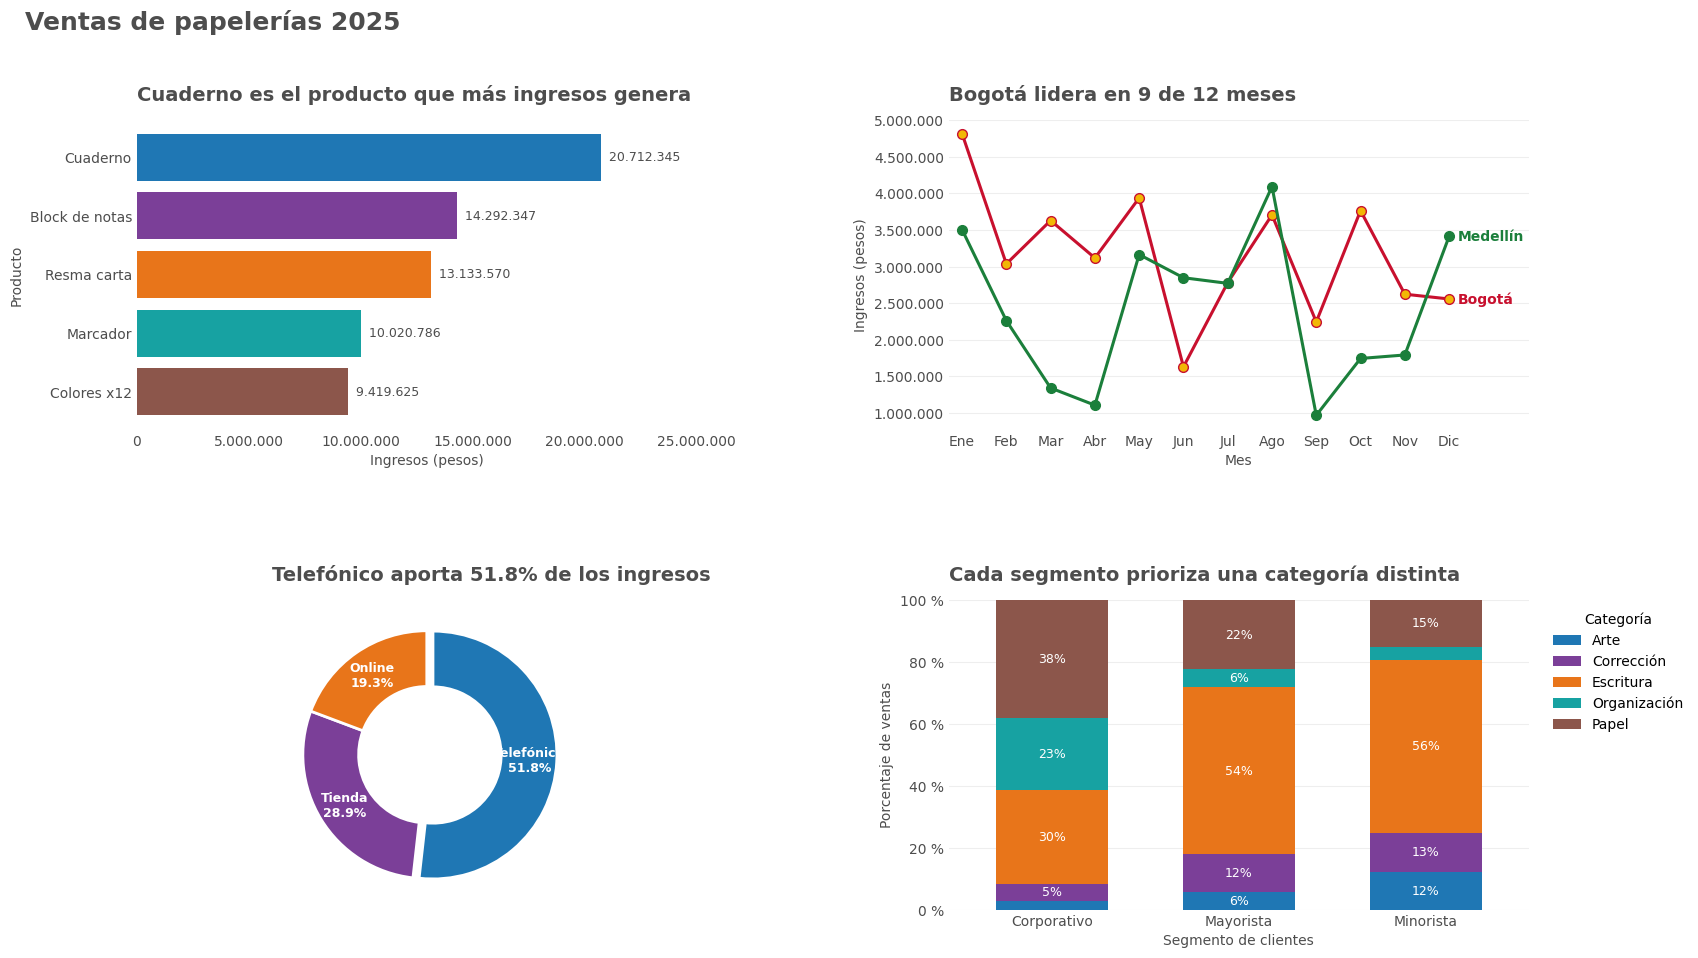

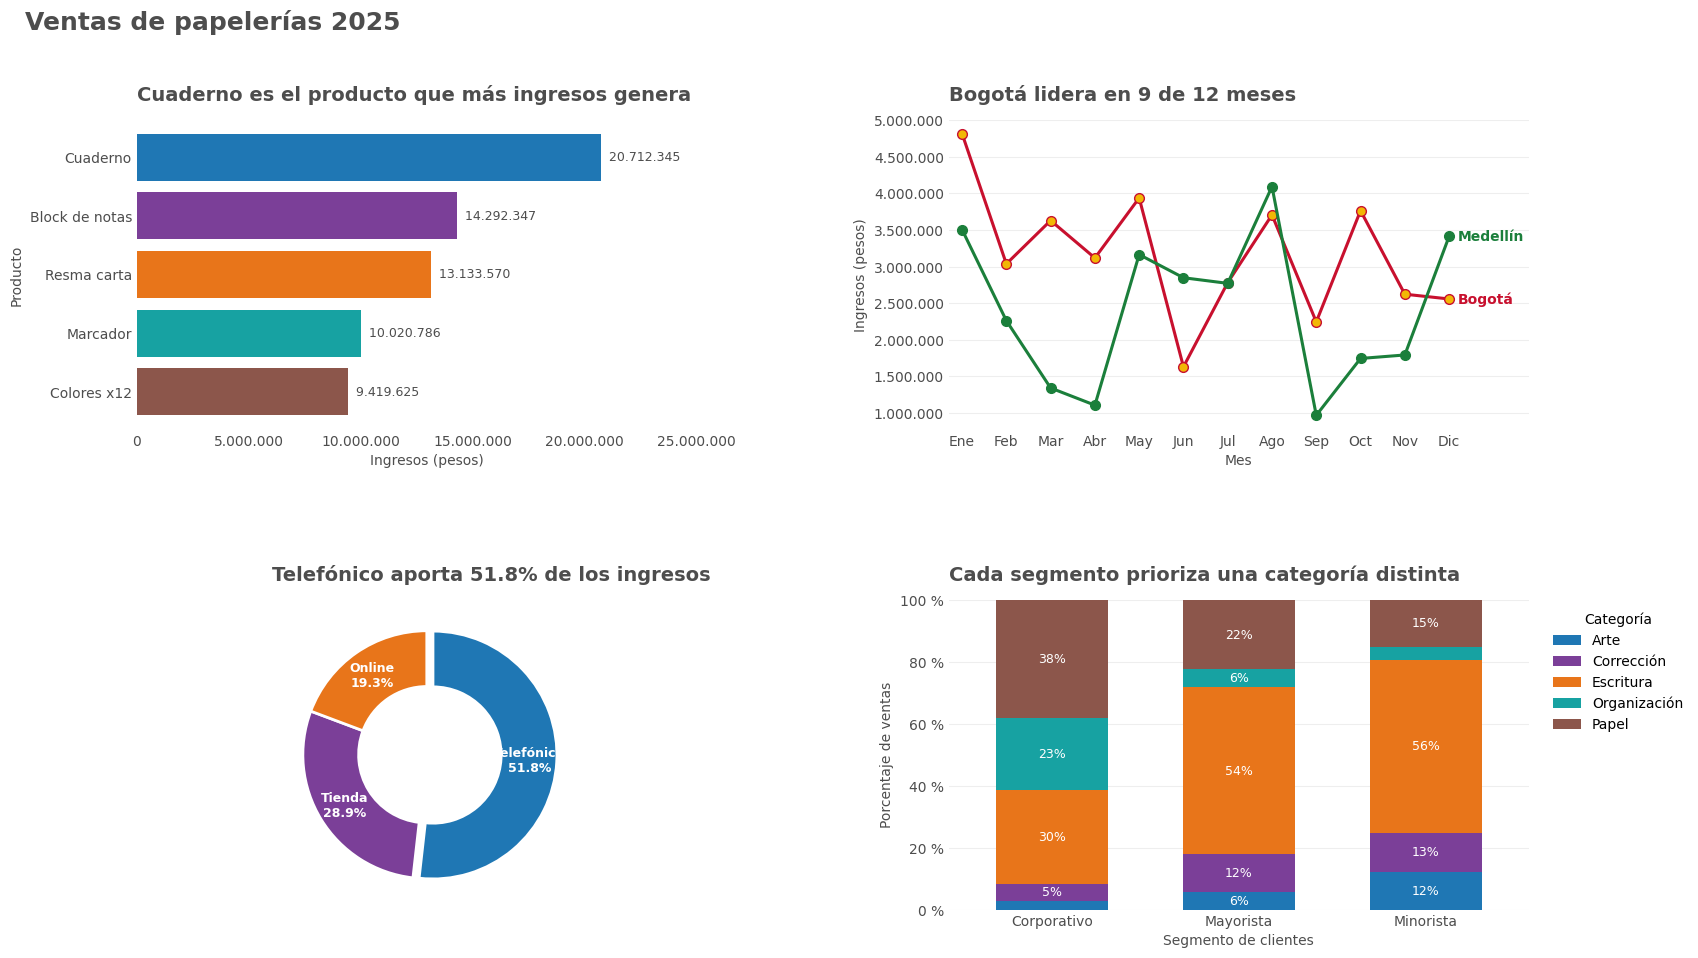

Hallazgos:
• Bogota lidera en 9 de los 12 meses
• Cuaderno es el producto que mas ingresos genera
• El producto que menos ingresos genera son los colores


In [88]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook).